# Descarga de HARPS para LHS 1140 (TOI-256)

Las secciones hasta **¿Que blaze uso este espectro?** vienen del notebook de Juan David. Desde **Descargar todos los .tar** es mi parte (paso 10.4 de su notebook).

Objetivo: bajar los **.tar** de HARPS, sacar el **e2ds_A** de cada uno y dejarlo en la estructura que pide LBL (**science/LHS1140/** y **calib/**). El resultado queda en Google Drive para el notebook de LBL.

Resultado final: 296 espectros descargados, 3 descartados por S/N bajo (S/N del orden 47 < 5), 293 listos para LBL.

**Orden de ejecucion:** corre las celdas de arriba hacia abajo, una vez. Cada celda usa variables de las anteriores (por ejemplo, el QC final usa UMBRAL_SNR, que se define en el descarte). En Colab los archivos se borran al cerrar la sesion: si se corta, vuelve a correr desde Importamos librerias; las celdas de descarga saltan lo que ya existe y el respaldo en Drive guarda el resultado.

Orden entre notebooks: descarga de HARPS, LBL, analisis de RV, transitos y zona habitable. Cada uno lee lo que deja el anterior (los espectros, el CSV de velocidades, el K de cada planeta).

## Instalacion y librerias

Solo hace falta **pyvo** (consultas al archivo de ESO). LBL se instala en el otro notebook.

In [ ]:
%pip install -Uq pyvo

### Importamos librerias

In [ ]:
import csv
import io
import shutil
import tarfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyvo
import requests
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.table import Table
from google.colab import drive
from scipy.ndimage import uniform_filter1d

### Letra grande para las figuras
Funcion que agranda las etiquetas de los ejes, los numeros y las leyendas de una figura para que se lean bien en el articulo.

In [ ]:
def letra_grande(fig, tam_etiqueta=14, tam_numeros=12, tam_leyenda=12):
    # etiquetas, numeros de los ejes y leyendas mas grandes, para el articulo
    for eje in fig.axes:
        eje.xaxis.label.set_size(tam_etiqueta)
        eje.yaxis.label.set_size(tam_etiqueta)
        eje.tick_params(labelsize=tam_numeros)
        leyenda = eje.get_legend()
        if leyenda is not None:
            for texto in leyenda.get_texts():
                texto.set_fontsize(tam_leyenda)

## Coordenadas de la estrella

**from_name** le pregunta a Sesame (CDS) donde esta el objeto. ESO pide las coordenadas en grados.

In [ ]:
LHS_1140_coord = SkyCoord.from_name("LHS 1140")
ra = LHS_1140_coord.ra.deg
dec = LHS_1140_coord.dec.deg
print(f"RA (grados): {ra}")
print(f"Dec (grados): {dec}")

RA (grados): 11.24721214
Dec (grados): -15.27153968


## Conexion al archivo de ESO

TAP es la ventanilla para hacerle preguntas al catalogo y ADQL es el idioma de las preguntas. Crear **tap** todavia no pregunta nada.

In [ ]:
tap = pyvo.dal.TAPService("https://archive.eso.org/tap_obs")
print(tap)

TAPService(baseurl : 'https://archive.eso.org/tap_obs', description : 'None')


## Observaciones cerca de la estrella

Se busca por posicion (circulo de 1 arcmin) y no por nombre, porque cada observador escribe el nombre distinto. Los nombres de columna (**s_ra**, **s_dec**) van sin **{}** y las variables de Python (**{ra}**, **{dec}**, **{radio}**) van con **{}**.

In [ ]:
radio = 1 / 60 # 1 arcmin, en grados

pregunta = f'''
SELECT dp_id, instrument_name, target_name, t_min, dataproduct_type, snr,
access_url
FROM ivoa.ObsCore
WHERE CONTAINS(POINT('ICRS', s_ra, s_dec),
               CIRCLE('ICRS', {ra}, {dec}, {radio})) = 1
'''

obs = tap.search(pregunta).to_table()
print(f"Productos encontrados: {len(obs)}")

Productos encontrados: 423


## Solo HARPS

Mascara de True/False: **&** es **y** y cada condicion va entre parentesis. Deben salir 296.

In [ ]:
HARPS = obs[(obs["instrument_name"] == "HARPS") & (obs["dataproduct_type"] == "spectrum")]
HARPS.sort("t_min")
print(f"Espectros de HARPS: {len(HARPS)}")

Espectros de HARPS: 296


## Funcion de descarga

- Si el archivo ya existe, no lo baja otra vez.
- Descarga de a 1 MB (**stream=True**) para no llenar la RAM.
- **raise_for_status()** frena si el servidor responde con error.
- Escribe en **.part** y renombra al final, asi un archivo final siempre esta completo.

In [ ]:
def descargar(url, destino):
    destino = Path(destino)
    if destino.exists():
        print(f"Ya existe, no lo bajo otra vez: {destino.name}")
        return destino
    destino.parent.mkdir(parents=True, exist_ok=True)
    temporal = destino.with_name(destino.name + ".part")

    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(temporal, "wb") as f:
            for pedazo in r.iter_content(chunk_size=1024*1024): # 1 MB
                f.write(pedazo)

    temporal.rename(destino)
    print(f"Descargado: {destino.name}")
    return destino

## Archivos de un producto de HARPS

Cada producto tiene solo 2 archivos: el espectro 1D (**SCIENCE.SPECTRUM**) y un **.tar** (**ANCILLARY.HARPSTAR**) con los productos intermedios. El que sirve para LBL es el **.tar**.

In [ ]:
un_producto_harps = HARPS["dp_id"][0]
print(f"Producto: {un_producto_harps}")

archivos_harps = tap.search(f'''
SELECT archive_id, eso_category, original_filename, access_url, access_estsize
FROM phase3v2.product_files
WHERE product_id = '{un_producto_harps}'
''').to_table()

archivos_harps["eso_category", "original_filename", "access_estsize"].pprint_all()

Producto: ADP.2015-11-24T02:01:17.473
   eso_category                          original_filename                       access_estsize
                                                                                     kbyte     
------------------ ------------------------------------------------------------- --------------
  SCIENCE.SPECTRUM HARPS.2015-11-23T02:59:06.381_s1d_A_DRS_HARPS_3.8_ESOSDP.fits           5264
ANCILLARY.HARPSTAR               HARPS.2015-11-23T02:59:06.381_DRS_HARPS_3.8.tar           6973


## Descargar y abrir un **.tar**

**tarfile.open** abre la caja sin sacar nada, **.getmembers()** lista lo que hay adentro (**.name**, **.size**) y **.extractfile()** lee un archivo sin guardarlo en disco.

Debe haber 11 archivos. El que usa LBL es **..._e2ds_A.fits** (4096 pixeles por 72 ordenes). El blaze **no** viene en el **.tar**.

In [ ]:
es_tar = [str(c) == "ANCILLARY.HARPSTAR" for c in archivos_harps["eso_category"]]
fila_tar = archivos_harps[es_tar][0]

ruta_tar = descargar(fila_tar["access_url"],
                     Path("datos_LHS_1140_TAR") / "HARPS" / (fila_tar["archive_id"] + ".tar"))

with tarfile.open(ruta_tar) as caja:
    for miembro in caja.getmembers():
        print(round(miembro.size / 1e6, 2), "MB", miembro.name)

Descargado: ADP.2015-11-24T02:01:17.500.tar
0.04 MB data/reduced/2015-11-22/HARPS.2015-11-23T02:59:06.381_INT_GUIDE.fits
0.25 MB data/reduced/2015-11-22/HARPS.2015-11-23T02:59:06.381_bis_M2_A.fits
0.25 MB data/reduced/2015-11-22/HARPS.2015-11-23T02:59:06.381_bis_M2_B.fits
0.3 MB data/reduced/2015-11-22/HARPS.2015-11-23T02:59:06.381_ccf_M2_A.fits
0.0 MB data/reduced/2015-11-22/HARPS.2015-11-23T02:59:06.381_ccf_M2_A.tbl
0.29 MB data/reduced/2015-11-22/HARPS.2015-11-23T02:59:06.381_ccf_M2_B.fits
0.0 MB data/reduced/2015-11-22/HARPS.2015-11-23T02:59:06.381_ccf_M2_B.tbl
1.43 MB data/reduced/2015-11-22/HARPS.2015-11-23T02:59:06.381_e2ds_A.fits
1.41 MB data/reduced/2015-11-22/HARPS.2015-11-23T02:59:06.381_e2ds_B.fits
1.5 MB data/reduced/2015-11-22/HARPS.2015-11-23T02:59:06.381_s1d_A.fits
1.5 MB data/reduced/2015-11-22/HARPS.2015-11-23T02:59:06.381_s1d_B.fits


## ¿Que blaze uso este espectro?

El pipeline anota en el header del **e2ds** que calibraciones uso. **extractfile(...).read()** da los bytes y **io.BytesIO** los envuelve para que **fits.open** los trate como un archivo.

In [ ]:
with tarfile.open(ruta_tar) as caja:
    for miembro in caja.getmembers():
        if miembro.name.endswith("e2ds_A.fits"):
            break
    datos = caja.extractfile(miembro).read()

with fits.open(io.BytesIO(datos)) as hdul:
    hdul.info()
    h = hdul[0].header
    for clave in h:
        if "BLAZE" in clave or "FLAT FILE" in clave or "TH FILE" in clave:
            print(clave, "=", h[clave])

Filename: <class '_io.BytesIO'>
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    3059   (4096, 72)   float32   
ESO DRS CAL FLAT FILE = HARPS.2015-11-22T20:22:37.879_flat_A.fits
ESO DRS BLAZE FILE = HARPS.2015-11-22T20:22:37.879_blaze_A.fits
ESO DRS CAL TH FILE = HARPS.2015-11-22T20:37:37.636_wave_A.fits
ESO DRS CAL TH FILE LINES = line_list_HARPS_A.dat


## Descargar todos los **.tar**

Ciclo sobre **HARPS**: para cada **dp_id** se consultan sus archivos, se deja la fila **ANCILLARY.HARPSTAR** y se baja el **.tar** (~7 MB cada uno, ~2 GB en total). En Colab todo se borra al cerrar la sesion, asi que despues se respalda en Drive (seccion Respaldo en Drive).

In [ ]:
for row in HARPS:
    # 1. Consultar los archivos de esta observacion
    archivos_harps = tap.search(f'''
    SELECT archive_id, eso_category, access_url
    FROM phase3v2.product_files
    WHERE product_id = '{row['dp_id']}'
    ''').to_table()

    # 2. Filtrar el .tar
    es_tar = [str(c) == "ANCILLARY.HARPSTAR" for c in archivos_harps["eso_category"]]
    fila_tar = archivos_harps[es_tar][0]

    # 3. Descargar (la funcion ya revisa si el archivo existe)
    descargar(fila_tar["access_url"],
              Path("datos_LHS_1140_TAR") / "HARPS" / (fila_tar["archive_id"] + ".tar"))

Ya existe, no lo bajo otra vez: ADP.2015-11-24T02:01:17.500.tar
Ya existe, no lo bajo otra vez: ADP.2015-11-24T02:01:17.327.tar
Ya existe, no lo bajo otra vez: ADP.2015-11-28T02:00:55.867.tar
Ya existe, no lo bajo otra vez: ADP.2015-11-28T02:00:56.770.tar
Ya existe, no lo bajo otra vez: ADP.2015-11-29T02:00:53.053.tar
Ya existe, no lo bajo otra vez: ADP.2015-11-29T02:00:53.517.tar
Ya existe, no lo bajo otra vez: ADP.2015-11-30T02:00:55.203.tar
Ya existe, no lo bajo otra vez: ADP.2015-11-30T02:00:55.993.tar
Ya existe, no lo bajo otra vez: ADP.2015-12-01T02:01:28.467.tar
Ya existe, no lo bajo otra vez: ADP.2015-12-01T02:01:29.053.tar
Ya existe, no lo bajo otra vez: ADP.2015-12-02T02:00:53.943.tar
Ya existe, no lo bajo otra vez: ADP.2015-12-02T02:00:53.197.tar
Ya existe, no lo bajo otra vez: ADP.2015-12-09T10:14:36.283.tar
Ya existe, no lo bajo otra vez: ADP.2015-12-09T10:14:36.037.tar
Ya existe, no lo bajo otra vez: ADP.2015-12-10T02:01:24.740.tar
Ya existe, no lo bajo otra vez: ADP.2015

## Sacar el **e2ds_A** de cada **.tar**

Se guarda en **science/LHS1140/**. Los **.tar** no traen el blaze, asi que solo se guarda el espectro.

In [ ]:
# carpeta de destino donde LBL buscara los datos
carpeta_destino = Path("science/LHS1140")
carpeta_destino.mkdir(parents=True, exist_ok=True)

# carpeta con los .tar descargados
directorio_tar = Path("datos_LHS_1140_TAR") / "HARPS"

for ruta_tar in directorio_tar.glob("*.tar"):
    with tarfile.open(ruta_tar) as caja:
        for miembro in caja.getmembers():
            if miembro.name.endswith("e2ds_A.fits"):
                break
        datos_e2ds = caja.extractfile(miembro).read()

    ruta_e2ds_salida = carpeta_destino / Path(miembro.name).name
    with open(ruta_e2ds_salida, "wb") as f:
        f.write(datos_e2ds)
    print("Guardado:", ruta_e2ds_salida.name)

Guardado: HARPS.2017-12-29T02:47:24.354_e2ds_A.fits
Guardado: HARPS.2016-09-30T05:12:05.085_e2ds_A.fits
Guardado: HARPS.2016-11-09T01:03:25.436_e2ds_A.fits
Guardado: HARPS.2017-08-02T06:50:28.173_e2ds_A.fits
Guardado: HARPS.2017-11-21T04:21:25.534_e2ds_A.fits
Guardado: HARPS.2016-12-29T00:57:45.447_e2ds_A.fits
Guardado: HARPS.2016-09-11T05:02:04.567_e2ds_A.fits
Guardado: HARPS.2016-01-18T01:39:42.943_e2ds_A.fits
Guardado: HARPS.2018-01-09T00:42:08.268_e2ds_A.fits
Guardado: HARPS.2016-10-27T05:44:11.117_e2ds_A.fits
Guardado: HARPS.2015-12-14T03:10:50.609_e2ds_A.fits
Guardado: HARPS.2017-11-16T04:38:05.578_e2ds_A.fits
Guardado: HARPS.2016-12-13T01:09:03.019_e2ds_A.fits
Guardado: HARPS.2017-10-28T05:39:50.006_e2ds_A.fits
Guardado: HARPS.2017-11-16T03:48:14.172_e2ds_A.fits
Guardado: HARPS.2018-01-07T01:39:31.641_e2ds_A.fits
Guardado: HARPS.2016-07-06T08:57:15.672_e2ds_A.fits
Guardado: HARPS.2016-08-30T06:25:43.933_e2ds_A.fits
Guardado: HARPS.2017-10-17T03:56:36.581_e2ds_A.fits
Guardado: HA

## Manifiesto y lista de blazes

Una fila por espectro con fecha, blaze, flat y wave. Sirve para saber que falta si se corta la descarga y para saber que nombres de blaze piden los espectros (147 distintos). **wave_A** no hace falta: LBL arma la longitud de onda con las claves **ESO DRS CAL TH COEFF LL*** del header.

### Manifiesto CSV
Una fila por espectro, con fecha, blaze, flat y wave.

In [ ]:
carpeta_ciencia = Path("science/LHS1140")
filas = []

for ruta in sorted(carpeta_ciencia.glob("*_e2ds_A.fits")):
    with fits.open(ruta) as hdul:
        h = hdul[0].header
        filas.append({
            "e2ds": ruta.name,
            "date_obs": h.get("DATE-OBS"),
            "mjd_obs": h.get("MJD-OBS"),
            "blaze": h.get("ESO DRS BLAZE FILE"),
            "flat": h.get("ESO DRS CAL FLAT FILE"),
            "wave": h.get("ESO DRS CAL TH FILE"),
        })

# manifiesto CSV
with open("manifiesto_LHS1140.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=filas[0].keys())
    w.writeheader()
    w.writerows(filas)

# blazes distintos
conteo = Counter(f["blaze"] for f in filas)
print(f"Espectros: {len(filas)} | Blazes distintos: {len(conteo)}")
for blaze, n in sorted(conteo.items()):
    print(n, blaze)

# verificacion contra lo esperado
print("¿Coincide con HARPS (296)?", len(filas) == len(HARPS))

Espectros: 296 | Blazes distintos: 147
2 HARPS.2015-11-22T20:22:37.879_blaze_A.fits
2 HARPS.2015-11-26T21:15:26.855_blaze_A.fits
2 HARPS.2015-11-27T16:19:50.854_blaze_A.fits
2 HARPS.2015-11-28T21:50:34.899_blaze_A.fits
2 HARPS.2015-11-29T19:49:33.182_blaze_A.fits
2 HARPS.2015-11-30T23:07:48.194_blaze_A.fits
2 HARPS.2015-12-07T20:42:17.557_blaze_A.fits
2 HARPS.2015-12-08T19:51:18.851_blaze_A.fits
2 HARPS.2015-12-09T20:33:33.574_blaze_A.fits
2 HARPS.2015-12-10T20:46:28.567_blaze_A.fits
2 HARPS.2015-12-13T19:42:00.571_blaze_A.fits
2 HARPS.2015-12-14T21:13:22.568_blaze_A.fits
2 HARPS.2015-12-15T20:57:06.638_blaze_A.fits
2 HARPS.2015-12-17T00:40:44.953_blaze_A.fits
2 HARPS.2015-12-18T01:44:20.955_blaze_A.fits
2 HARPS.2016-01-01T18:38:36.150_blaze_A.fits
2 HARPS.2016-01-02T16:22:20.139_blaze_A.fits
1 HARPS.2016-01-13T18:53:48.187_blaze_A.fits
2 HARPS.2016-01-16T20:16:06.543_blaze_A.fits
2 HARPS.2016-01-17T23:56:47.338_blaze_A.fits
2 HARPS.2016-01-19T22:02:04.843_blaze_A.fits
1 HARPS.2016-01-

### Listas de blazes y waves necesarios
Nombres distintos que piden los espectros. Crea tambien la carpeta **calib/**.

In [ ]:
m = pd.read_csv("manifiesto_LHS1140.csv")

pd.Series(sorted(m["blaze"].unique())).to_csv("blazes_necesarios.csv", index=False, header=["blaze"])
pd.Series(sorted(m["wave"].unique())).to_csv("waves_necesarios.csv", index=False, header=["wave"])
Path("calib").mkdir(exist_ok=True)
print(m["blaze"].nunique(), "blazes |", m["wave"].nunique(), "waves")

147 blazes | 147 waves


## Respaldo en Drive

### Copiar a Drive
Respalda **science/** y los **.tar**, mas el manifiesto y las listas.

In [ ]:
drive.mount("/content/drive")

destino = Path("/content/drive/MyDrive/LHS1140_HARPS")
destino.mkdir(parents=True, exist_ok=True)

# carpetas completas (calib se respalda mas abajo, en la seccion Blaze)
for carpeta in ["science", "datos_LHS_1140_TAR"]:
    origen = Path(carpeta)
    if origen.exists():
        shutil.copytree(origen, destino / carpeta, dirs_exist_ok=True)
        print(f"Copiada carpeta: {carpeta}")

# archivos sueltos (manifiesto y listas)
for archivo in ["manifiesto_LHS1140.csv", "blazes_necesarios.csv", "waves_necesarios.csv"]:
    origen = Path(archivo)
    if origen.exists():
        shutil.copy2(origen, destino / archivo)
        print(f"Copiado archivo: {archivo}")

print("\nListo. Respaldo en:", destino)

Mounted at /content/drive
Copiada carpeta: science
Copiada carpeta: datos_LHS_1140_TAR
Copiado archivo: manifiesto_LHS1140.csv
Copiado archivo: blazes_necesarios.csv
Copiado archivo: waves_necesarios.csv

Listo. Respaldo en: /content/drive/MyDrive/LHS1140_HARPS


### Verificar el respaldo
Debe haber 296 **e2ds** y 296 **.tar** en Drive.

In [ ]:
n_e2ds = len(list((destino / "science" / "LHS1140").glob("*_e2ds_A.fits")))
n_tar = len(list((destino / "datos_LHS_1140_TAR" / "HARPS").glob("*.tar")))
print(f"En Drive: {n_e2ds} e2ds | {n_tar} .tar")

En Drive: 296 e2ds | 296 .tar


## Blaze

El blaze es una calibracion del instrumento (lampara de tungsteno) y no depende de la estrella. El header de cada **e2ds** pide el blaze de su noche (147 nombres distintos, entre noviembre de 2015 y enero de 2018), pero esos archivos no estan en el archivo de ESO: una busqueda de **blaze_A** en **product_files** devuelve 0 resultados y los **.tar** no los traen.

En su lugar se usa **HARPS_BLAZE_A_72.fits** del taller de velocidades radiales con LBL del semillero COSMIA-UdeA (Camilo Ospinal), que recomendo el lider del semillero (ver referencia abajo). Es una calibracion del 19 de marzo de 2016 (programa 60.A-9036(A) de ESO), dentro del rango de las observaciones. Se guarda en Drive y se hace una copia con cada uno de los 147 nombres que piden los espectros, porque LBL busca el blaze por el nombre que aparece en el header.

**Limitacion:** todas las epocas usan el mismo blaze, no el de su noche, y no se midio cuanto cambia esto las velocidades radiales. La auditoria de la seccion siguiente solo revisa que el **e2ds** y el blaze tengan la misma forma.

Referencia: COSMIA-UdeA, **Taller de velocidades radiales con LBL**, GitHub, https://github.com/COSMIA-UdeA/Taller-Velocidades-Radiales-LBL, consultado el 22 de noviembre de 2026.

### Copiar el blaze unico desde Drive

In [ ]:
drive.mount("/content/drive")

origen = Path("/content/drive/MyDrive/LHS1140_HARPS/HARPS_BLAZE_A_72.fits")
shutil.copy2(origen, "HARPS_BLAZE_A_72.fits") # copia local, mas rapida de leer

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


'HARPS_BLAZE_A_72.fits'

### Crear una copia por cada nombre de blaze
Se guardan en **calib/** con los 147 nombres que piden los espectros.

In [ ]:
# leer el blaze (los datos estan en la extension BLAZE)
with fits.open("HARPS_BLAZE_A_72.fits") as hdul:
    blaze = np.array(hdul["BLAZE"].data, dtype="float64")
    hdr = hdul[0].header.copy()

calib = Path("calib")
calib.mkdir(exist_ok=True)

# una copia por cada nombre que piden los espectros
nombres = pd.read_csv("blazes_necesarios.csv")["blaze"]
for nombre in nombres:
    fits.PrimaryHDU(data=blaze, header=hdr).writeto(calib / nombre, overwrite=True)

print(len(list(calib.glob("*_blaze_A.fits"))), "blazes en calib/") # debe dar 147

147 blazes en calib/


### Verificar que no falta ninguno
Debe salir **[]**.

In [ ]:
m = pd.read_csv("manifiesto_LHS1140.csv")
faltan = [b for b in m["blaze"].unique() if not (calib / b).exists()]
print("Faltan:", faltan) # debe salir []

Faltan: []


### Respaldar **calib/** en Drive

In [ ]:
drive.mount("/content/drive") # si ya esta montado, no pasa nada

destino = Path("/content/drive/MyDrive/LHS1140_HARPS")
destino.mkdir(parents=True, exist_ok=True)

print("Locales en calib/:", len(list(Path("calib").glob("*_blaze_A.fits"))))

shutil.copytree("calib", destino / "calib", dirs_exist_ok=True)

print("En Drive:", len(list((destino / "calib").glob("*_blaze_A.fits"))), "blazes")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Locales en calib/: 147
En Drive: 147 blazes


## Auditoria del blaze por epoca y descarte por S/N

Para cada espectro se calcula la correlacion de Pearson entre el **e2ds** suavizado y el blaze, orden por orden. Si la correlacion media baja, el blaze no le sirve a esa epoca. Luego se mira si eso depende de la S/N y se descartan los espectros con S/N(orden 47) < 5 (se mueven a **science/LHS1140_descartados/**, es reversible).

### Correlacion por orden
Para cada espectro, **r** entre el **e2ds** suavizado y el blaze, orden por orden.

In [ ]:
carpeta_ciencia = Path("science/LHS1140")
calib = Path("calib")
ORDENES_DUDOSOS = [19, 43, 56, 64, 71] # valor elegido en este trabajo
ORDEN_MIN = 5 # LBL excluye los ordenes con longitud de onda menor a 400 nm
VENTANA = 101 # pixeles de suavizado, valor elegido en este trabajo

def r_por_orden(e2ds, blaze):
    """Correlacion de Pearson entre e2ds suavizado y blaze, orden por orden."""
    r = np.full(e2ds.shape[0], np.nan)
    for o in range(e2ds.shape[0]):
        y = np.nan_to_num(e2ds[o])
        if y.max() <= 0:
            continue
        ys = uniform_filter1d(y, VENTANA)
        r[o] = np.corrcoef(ys, blaze[o])[0, 1]
    return r

filas = []
for ruta in sorted(carpeta_ciencia.glob("*_e2ds_A.fits")):
    with fits.open(ruta) as hdul:
        e2ds = np.array(hdul[0].data, dtype="float64")
        h = hdul[0].header
        nombre_blaze = h.get("ESO DRS BLAZE FILE")
        mjd = h.get("MJD-OBS")

    with fits.open(calib / nombre_blaze) as hb:
        blaze = np.array(hb[0].data, dtype="float64")

    r = r_por_orden(e2ds, blaze)
    fila = {"archivo": ruta.name, "mjd": mjd}
    fila.update({f"o{o}": r[o] for o in range(len(r))})
    filas.append(fila)

df = pd.DataFrame(filas).sort_values("mjd").reset_index(drop=True)
cols_buenas = [f"o{o}" for o in range(ORDEN_MIN, 72)]
df["r_medio"] = df[cols_buenas].mean(axis=1)
df.to_csv("auditoria_blaze_por_epoca.csv", index=False)
print(f"{len(df)} espectros auditados")

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


296 espectros auditados


### r medio contra la fecha
A la izquierda, el **r** medio de cada espectro contra su MJD. A la derecha, **r** contra el MJD solo en los ordenes dudosos. Si el blaze de 2016 no sirviera para las otras epocas, **r** bajaria lejos de esa fecha.

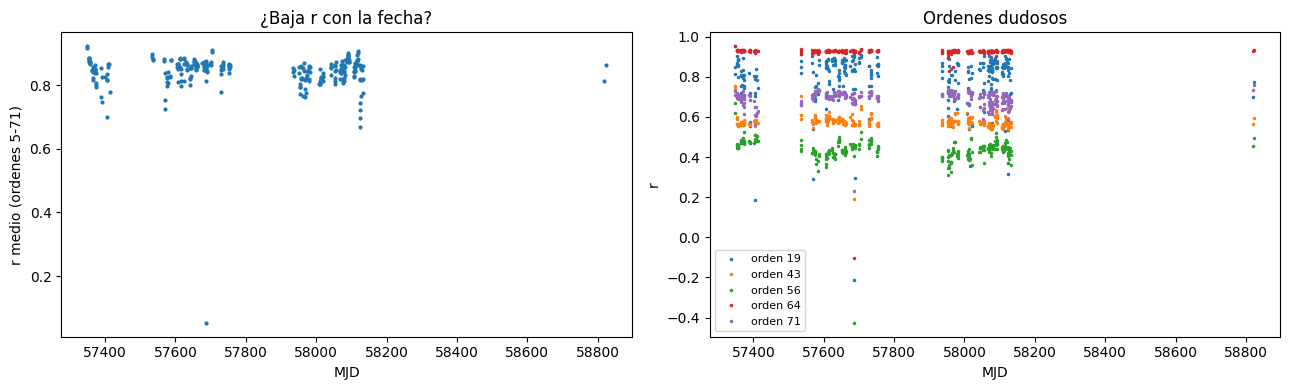

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(df["mjd"], df["r_medio"], ".", ms=4)
ax[0].set_xlabel("MJD")
ax[0].set_ylabel(f"r medio (ordenes {ORDEN_MIN}-71)")
ax[0].set_title("¿Baja r con la fecha?")

for o in ORDENES_DUDOSOS:
    ax[1].plot(df["mjd"], df[f"o{o}"], ".", ms=3, label=f"orden {o}")
ax[1].set_xlabel("MJD")
ax[1].set_ylabel("r")
ax[1].set_title("Ordenes dudosos")
ax[1].legend(fontsize=8)
letra_grande(fig)
plt.tight_layout()
plt.savefig("auditoria_r_vs_fecha.png", dpi=130)
plt.show()

### Residuos e2ds / blaze
Se divide el **e2ds** entre el blaze en el primer y el ultimo espectro, orden por orden. Si el blaze sirve, el cociente (normalizado) debe verse plano.

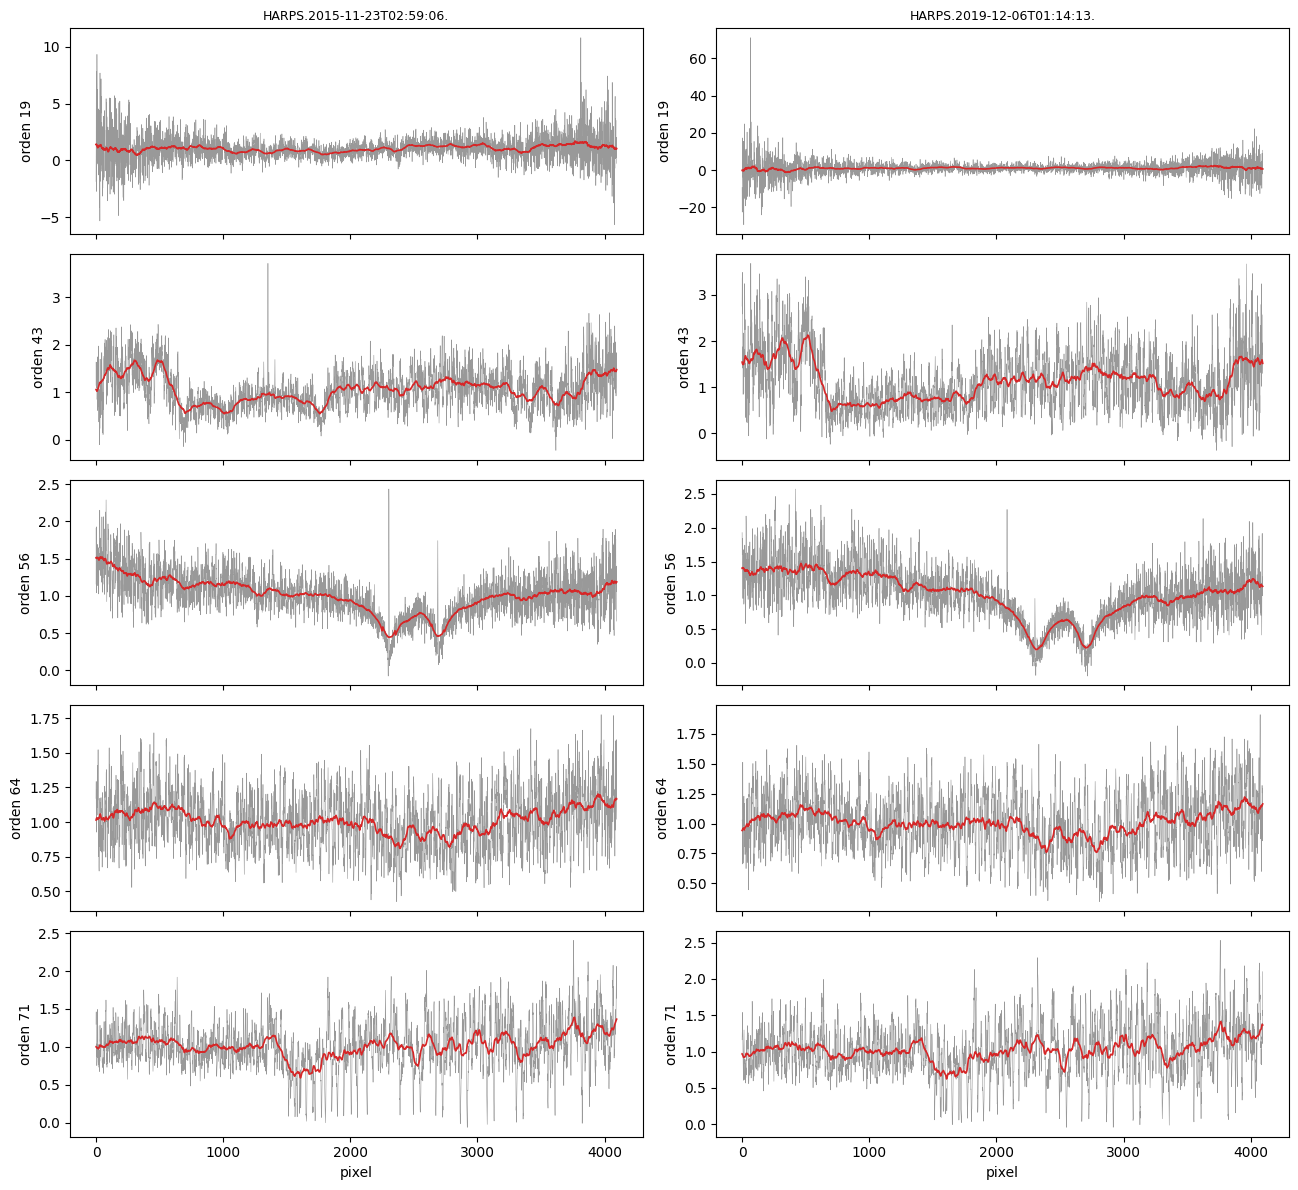

In [ ]:
fig, axs = plt.subplots(len(ORDENES_DUDOSOS), 2, figsize=(13, 2.4 * len(ORDENES_DUDOSOS)), sharex=True)
for j, idx in enumerate([0, len(df) - 1]):
    nombre = df.loc[idx, "archivo"]
    with fits.open(carpeta_ciencia / nombre) as hdul:
        e2ds = np.array(hdul[0].data, dtype="float64")
        nombre_blaze = hdul[0].header.get("ESO DRS BLAZE FILE")
    with fits.open(calib / nombre_blaze) as hb:
        blaze = np.array(hb[0].data, dtype="float64")

    for i, o in enumerate(ORDENES_DUDOSOS):
        res = np.nan_to_num(e2ds[o]) / blaze[o]
        res = res / np.nanmedian(res)
        axs[i, j].plot(res, lw=0.4, color="0.6")
        axs[i, j].plot(uniform_filter1d(res, VENTANA), lw=1.2, color="C3")
        axs[i, j].set_ylabel(f"orden {o}")
    axs[0, j].set_title(nombre[:26], fontsize=9)
axs[-1, 0].set_xlabel("pixel")
axs[-1, 1].set_xlabel("pixel")
plt.tight_layout()
plt.savefig("auditoria_residuos.png", dpi=130)
plt.show()

### ¿Depende de la S/N?
Se revisa si **r** baja cuando baja la S/N del orden 47.

                                       archivo           mjd   r_medio  snr47
123  HARPS.2016-10-25T02:49:42.127_e2ds_A.fits  57686.117849  0.053482    0.1
283  HARPS.2018-01-07T01:39:31.641_e2ds_A.fits  58125.069116  0.667778    7.9
285  HARPS.2018-01-07T02:42:42.582_e2ds_A.fits  58125.112993  0.696069    7.8
38   HARPS.2016-01-18T02:10:14.373_e2ds_A.fits  57405.090444  0.698793    3.4
284  HARPS.2018-01-07T02:11:07.057_e2ds_A.fits  58125.091054  0.721532    9.7
50   HARPS.2016-06-30T08:46:58.674_e2ds_A.fits  57569.365957  0.723792    4.5
282  HARPS.2018-01-06T01:21:50.478_e2ds_A.fits  58124.056834  0.744311    6.2
33   HARPS.2016-01-03T01:12:15.136_e2ds_A.fits  57390.050175  0.747744    8.4


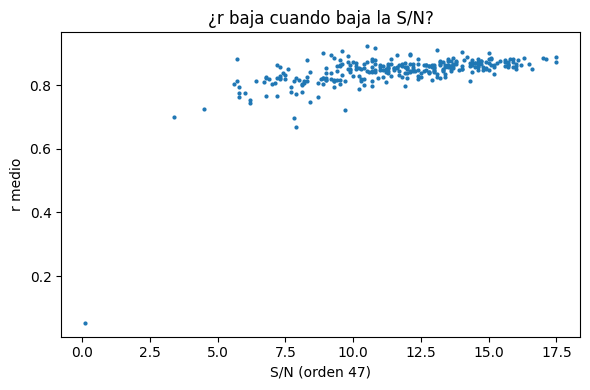

In [ ]:
def leer_snr(ruta):
    with fits.open(ruta) as h:
        return h[0].header.get("ESO DRS SPE EXT SN47")

df["snr47"] = [leer_snr(carpeta_ciencia / a) for a in df["archivo"]]

print(df.nsmallest(8, "r_medio")[["archivo", "mjd", "r_medio", "snr47"]])

plt.figure(figsize=(6, 4))
plt.plot(df["snr47"], df["r_medio"], ".", ms=4)
plt.xlabel("S/N (orden 47)")
plt.ylabel("r medio")
plt.title("¿r baja cuando baja la S/N?")
plt.tight_layout()
plt.show()

### Descartar los espectros con S/N bajo
Se mueven a **science/LHS1140_descartados/** (reversible).

In [ ]:
UMBRAL_SNR = 5 # LBL usa 10 por defecto; se bajo a 5 en el notebook de LBL (valor elegido en este trabajo)

df["excluir"] = df["snr47"] < UMBRAL_SNR
print("Excluidos:", df["excluir"].sum(), "de", len(df))
print(df[df["excluir"]][["archivo", "mjd", "snr47", "r_medio"]])

# mover los excluidos fuera de science/ (reversible)
descartados = Path("science/LHS1140_descartados")
descartados.mkdir(exist_ok=True)
for a in df.loc[df["excluir"], "archivo"]:
    (carpeta_ciencia / a).rename(descartados / a)

df.to_csv("auditoria_blaze_por_epoca.csv", index=False)

Excluidos: 3 de 296
                                       archivo           mjd  snr47   r_medio
38   HARPS.2016-01-18T02:10:14.373_e2ds_A.fits  57405.090444    3.4  0.698793
50   HARPS.2016-06-30T08:46:58.674_e2ds_A.fits  57569.365957    4.5  0.723792
123  HARPS.2016-10-25T02:49:42.127_e2ds_A.fits  57686.117849    0.1  0.053482


### Actualizar Drive
Se respaldan los descartados y se quitan de **science/LHS1140/** en Drive. Deben quedar 293.

In [ ]:
drive_sci = Path("/content/drive/MyDrive/LHS1140_HARPS/science")
shutil.copytree("science/LHS1140_descartados", drive_sci / "LHS1140_descartados", dirs_exist_ok=True)
for archivo in Path("science/LHS1140_descartados").glob("*_e2ds_A.fits"):
    (drive_sci / "LHS1140" / archivo.name).unlink(missing_ok=True)
print(len(list((drive_sci / "LHS1140").glob("*_e2ds_A.fits"))), "e2ds en Drive") # debe dar 293

293 e2ds en Drive


## QC final

Revision de lo que va a leer LBL: objeto, numero de coeficientes de wave, version del DRS, tipo de observacion y S/N. Todo debe ser homogeneo en los 293 espectros.

Esto es lo que LBL lee de cada **e2ds** (segun la revision del codigo fuente de LBL, lbl/instruments/harps.py, https://github.com/njcuk9999/lbl):
- Longitud de onda: se arma con las 288 claves **ESO DRS CAL TH COEFF LL** del header. LBL no abre los archivos wave_A.
- Blaze: busca en **calib/** un archivo con el nombre de **ESO DRS BLAZE FILE**.
- S/N: usa **ESO DRS SPE EXT SN47** (orden 47). El umbral por defecto es 10 y aqui se bajo a 5.
- Clase de instrumento: **HARPS** y no **HARPS_ESO**, que es para los productos reprocesados del SDP (s1d y s2d).

### Tabla de QC
Una fila por **e2ds**, con las claves del header que lee LBL.

In [ ]:
RAIZ = Path(".") # si se trabaja directo desde Drive: Path("/content/drive/MyDrive/LHS1140_HARPS")

filas = []
for ruta in sorted((RAIZ / "science" / "LHS1140").glob("*_e2ds_A.fits")):
    with fits.open(ruta) as hdul:
        h = hdul[0].header
        coefs = [k for k in h if k.startswith("ESO DRS CAL TH COEFF LL")]
        filas.append({
            "e2ds": ruta.name,
            "objeto": h.get("ESO OBS TARG NAME"),
            "dpr_type": h.get("ESO DPR TYPE"),
            "drs_version": h.get("ESO DRS VERSION"),
            "snr47": h.get("ESO DRS SPE EXT SN47"),
            "n_coef_wave": len(coefs),
            "blaze": h.get("ESO DRS BLAZE FILE"),
            "bjd": h.get("ESO DRS BJD"),
            "berv": h.get("ESO DRS BERV"),
        })

qc = pd.DataFrame(filas)
qc.to_csv(RAIZ / "qc_LHS1140.csv", index=False)

print("Objetos (debe ser solo LHS1140):")
print(qc["objeto"].value_counts())
print("Coeficientes de wave por archivo (debe ser solo 288):")
print(qc["n_coef_wave"].value_counts())
print("Versiones DRS:")
print(qc["drs_version"].value_counts(dropna=False))
print("DPR TYPE:")
print(qc["dpr_type"].value_counts())
print("SNR47: min", round(qc["snr47"].min(), 1), "| mediana", round(qc["snr47"].median(), 1), "| max", round(qc["snr47"].max(), 1))
print("Espectros con SNR47 < 10 (umbral por defecto de LBL):", (qc["snr47"] < 10).sum())
print("Espectros sin BJD o sin BERV:", qc["bjd"].isna().sum() + qc["berv"].isna().sum())

Objetos (debe ser solo LHS1140):
objeto
LHS1140    293
Name: count, dtype: int64
Coeficientes de wave por archivo (debe ser solo 288):
n_coef_wave
288    293
Name: count, dtype: int64
Versiones DRS:
drs_version
HARPS_3.8    293
Name: count, dtype: int64
DPR TYPE:
dpr_type
STAR,SKY,M0    293
Name: count, dtype: int64
SNR47: min 5.6 | mediana 11.8 | max 17.5
Espectros con SNR47 < 10 (umbral por defecto de LBL): 86
Espectros sin BJD o sin BERV: 0


### Cada e2ds encuentra su blaze
Para cada nombre de blaze que piden los espectros se revisa que exista en **calib/**, que **fits.getdata** lo lea con forma (72, 4096) y que no tenga NaN ni inf.

In [ ]:
calib = RAIZ / "calib"
problemas = []

for blaze in qc["blaze"].unique():
    ruta = calib / blaze
    if not ruta.exists():
        problemas.append((blaze, "no existe"))
        continue
    datos = fits.getdata(ruta)
    if datos.shape != (72, 4096):
        problemas.append((blaze, "la forma no es (72, 4096)"))
    elif not np.isfinite(datos).all():
        problemas.append((blaze, "tiene NaN o inf"))

if len(problemas) > 0:
    print("Problemas:")
    for blaze, detalle in problemas:
        print(blaze, detalle)
else:
    print("OK: los", qc["blaze"].nunique(), "blazes existen, tienen forma (72, 4096) y no tienen NaN ni inf")

OK: los 147 blazes existen, tienen forma (72, 4096) y no tienen NaN ni inf


### Resumen
Todos los chequeos deben salir **OK**. El de la S/N se compara con **UMBRAL_SNR** (5, definido en la seccion de descarte) y no con el 10 por defecto de LBL, porque el umbral se bajo a 5 en el notebook de LBL.

In [ ]:
chequeos = {
    "293 e2ds en science/LHS1140/": len(qc) == 293,
    "todos los archivos son LHS1140": (qc["objeto"] == "LHS1140").all(),
    "288 coeficientes de wave en todos": (qc["n_coef_wave"] == 288).all(),
    "BJD presente en todos": qc["bjd"].notna().all(),
    "BERV presente en todos": qc["berv"].notna().all(),
    "blazes completos en calib/": len(problemas) == 0,
    "SNR47 mayor o igual que UMBRAL_SNR": (qc["snr47"] >= UMBRAL_SNR).all(),
}
for nombre, ok in chequeos.items():
    if ok:
        print("OK", nombre)
    else:
        print("REVISAR", nombre)

OK 293 e2ds en science/LHS1140/
OK todos los archivos son LHS1140
OK 288 coeficientes de wave en todos
OK BJD presente en todos
OK BERV presente en todos
OK blazes completos en calib/
OK SNR47 mayor o igual que UMBRAL_SNR
